# Direct three-month egg price forecasts

This experiment keeps **two hidden layers of 30 ReLU neurons each**, but replaces
the softmax classifier with **three linear outputs**. They represent cumulative
log-price changes from the latest observed price, one per forecast horizon.

**Architecture:** 12 recent monthly log changes → 30 ReLU + dropout → 30 ReLU +
dropout → 3 linear outputs → 3 positive dollar forecasts.

The decoder is $\widehat P_{t+h}=P_t\exp(z_h)$ for $h=1,2,3$. Zero output means
the naive forecast $\widehat P_{t+h}=P_t$. We initialize the output weights and
biases to zero, then learn adjustments by minimizing **mean squared dollar
forecast error**. The three predictions are issued together. Predictions never
become inputs to later horizons.

Training duration and weight decay are selected using rolling-origin validation
strictly before November 2024. The existing November–January validation and
February–April test results are reported only after the settings are locked.
We have already examined the final test period in earlier experiments, so it
remains an exploratory comparison rather than a new untouched test.

Use a Python 3 kernel with the packages in `requirements-neural-network.txt`.


In [1]:
from pathlib import Path
import csv
import hashlib
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
import matplotlib.dates as mdates

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#172554', 'text.color': '#172554',
    'axes.titleweight': 'bold', 'font.size': 10,
})
COLORS = {'observed': '#172554', 'gd': '#2563eb', 'naive': '#b45309',
          'actual': '#0f766e'}

# Locate the project from either the repository root or analysis/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'APU0000708111.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside the egg-onomics project.')
INPUT = ROOT / 'data' / 'APU0000708111.csv'
# Keep this experiment separate from the R outputs; override for a scratch run.
OUT = Path(os.environ.get('EGG_DIRECT_NN_OUTPUT', str(ROOT / 'results' / 'direct_neural_network')))
OUT.mkdir(parents=True, exist_ok=True)

with INPUT.open(newline='', encoding='utf-8-sig') as handle:
    rows = list(csv.DictReader(handle))
dates = np.array([r['observation_date'] for r in rows], dtype='datetime64[M]')
prices = np.array([float(r['APU0000708111']) for r in rows])
month_index = np.arange(len(prices), dtype=float)
expected = np.arange(np.datetime64('1980-01', 'M'), np.datetime64('2025-05', 'M'))
assert len(prices) == 544 and np.array_equal(dates, expected)
assert np.isfinite(prices).all() and (prices > 0).all()
source_md5 = hashlib.md5(INPUT.read_bytes()).hexdigest()
assert source_md5 == 'bf246189cbf9d52a5da338e57f838d30'
print(f'{len(prices)} observed monthly prices: {dates[0]} to {dates[-1]}')
print('Missing months: 0. Missing prices: 0. No filling or interpolation.')

print('PyTorch', torch.__version__)


544 observed monthly prices: 1980-01 to 2025-04
Missing months: 0. Missing prices: 0. No filling or interpolation.
PyTorch 2.14.1+cpu


## Changes from the classifier

- Inputs are the last 12 monthly log changes, $\log(P_s/P_{s-1})$, rather than
  absolute price levels. Constructing them requires 13 observed prices.
- The latest observed price anchors all forecasts. There are no price bins or
  bounds imposed by bin centers.
- Three outputs predict all three horizons directly, avoiding recursive inputs.
- Dollar MSE matches the forecasting objective; gradients pass through the
  exponential decoder. These are dollar point forecasts, without an additional
  lognormal bias correction or estimated prediction intervals.
- Dropout is fixed at 0.10. We compare weight decay 0.001 and 0.01, each at
  25, 75, 150 and 300 Adam updates. Learning rate is fixed at 0.003 and seed at 42.
  The choices below are made before scoring the outer validation or test period.


In [2]:
LAGS, HIDDEN, HORIZON = 12, 30, 3
SEED, LEARNING_RATE, DROPOUT = 42, 0.003, 0.10
WEIGHT_DECAYS = [0.001, 0.01]
CHECKPOINTS = [25, 75, 150, 300]
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

class DirectPriceNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(LAGS, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN, HORIZON),
        )
        # Begin at zero change from the latest price: exactly the naive forecast.
        nn.init.zeros_(self.layers[-1].weight)
        nn.init.zeros_(self.layers[-1].bias)

    def forward(self, x):
        return self.layers(x)

def training_examples(end):
    """Every target month must be observed strictly before end."""
    anchors = np.arange(LAGS, end - HORIZON)
    X = np.stack([np.diff(np.log(prices[i - LAGS:i + 1])) for i in anchors])
    targets = np.stack([prices[i + 1:i + HORIZON + 1] for i in anchors])
    base = prices[anchors]
    assert anchors[-1] + HORIZON == end - 1
    return X, base, targets, anchors

def score(actual, forecast):
    error = np.asarray(actual) - np.asarray(forecast)
    return dict(MAE=float(np.mean(np.abs(error))),
                RMSE=float(np.sqrt(np.mean(error ** 2))),
                MAPE=float(100 * np.mean(np.abs(error / actual))))

def predict_direct(model, observed_history):
    """Use one observed history to produce all three forecasts at once."""
    history = np.asarray(observed_history, dtype=float)
    assert len(history) == model['end']
    changes = np.diff(np.log(history[-LAGS - 1:]))
    x = (changes - model['center']) / model['scale']
    model['network'].eval()
    with torch.no_grad():
        delta = model['network'](torch.tensor(x[None, :], dtype=torch.float32))
        forecast = history[-1] * torch.exp(delta).numpy()[0].astype(float)
    assert np.isfinite(forecast).all() and (forecast > 0).all()
    return forecast

def fit_path(end, weight_decay, checkpoints):
    torch.manual_seed(SEED)
    X, base, targets, anchors = training_examples(end)
    center, scale = X.mean(axis=0), np.maximum(X.std(axis=0), 1e-8)
    x = torch.tensor((X - center) / scale, dtype=torch.float32)
    anchor_price = torch.tensor(base[:, None], dtype=torch.float32)
    y = torch.tensor(targets, dtype=torch.float32)
    network = DirectPriceNetwork()
    optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE,
                                 weight_decay=weight_decay)
    model = dict(network=network, center=center, scale=scale, end=end,
                 training_examples=len(anchors), last_target=int(anchors[-1] + HORIZON))
    losses, forecasts = [], {}

    def training_mse():
        network.eval()
        with torch.no_grad():
            return float(torch.mean((anchor_price * torch.exp(network(x)) - y) ** 2))

    losses.append(training_mse())
    for epoch in range(1, max(checkpoints) + 1):
        network.train()
        optimizer.zero_grad()
        predicted_prices = anchor_price * torch.exp(network(x))
        loss = torch.mean((predicted_prices - y) ** 2)
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite dollar loss')
        loss.backward()
        nn.utils.clip_grad_norm_(network.parameters(), max_norm=5.0)
        optimizer.step()
        losses.append(training_mse())
        if epoch in checkpoints:
            forecasts[epoch] = predict_direct(model, prices[:end])
    model.update(losses=np.array(losses), weight_decay=weight_decay, epochs=max(checkpoints))
    assert all(torch.isfinite(p).all() for p in network.parameters())
    return model, forecasts

parameter_count = sum(p.numel() for p in DirectPriceNetwork().parameters())
assert parameter_count == (12 + 1) * 30 + (30 + 1) * 30 + (30 + 1) * 3 == 1413
print(DirectPriceNetwork())
print(f'Trainable parameters: {parameter_count:,}')


DirectPriceNetwork(
  (layers): Sequential(
    (0): Linear(in_features=12, out_features=30, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=30, out_features=30, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=30, out_features=3, bias=True)
  )
)
Trainable parameters: 1,413


## Select settings on historical rolling origins

There are 12 quarterly forecast origins from October 2021 through July 2024.
Each predicts the next three months. Their 36 target months are disjoint and
end in October 2024. This includes both price increases and declines.

Each origin constructs training examples and scaling from its available history
only. A three-month training example is excluded if any target falls after the
origin. All eight candidate settings see the same rolling validation outcomes.
We select the lowest **pooled dollar RMSE over the 36 outcomes**. Selecting a
checkpoint this way chooses training duration using chronological validation,
instead of assuming that 800 updates is appropriate.

The curve is useful for selection, but its winning score is optimistic because
we used those folds to choose the settings. The later validation and test
windows are additional checks. No random train/test split is used.


In [3]:
first_cv_end = int(np.flatnonzero(dates == np.datetime64('2021-10'))[0]) + 1
outer_validation_end = len(prices) - 6
cv_origins = list(range(first_cv_end, outer_validation_end - HORIZON + 1, HORIZON))
assert len(cv_origins) == 12
assert max(cv_origins) + HORIZON <= outer_validation_end
cv_rows, cv_folds, cv_naive_rows = [], [], []
for end in cv_origins:
    cv_folds.append(dict(origin=str(dates[end - 1]),
        forecast_start=str(dates[end]), forecast_end=str(dates[end + HORIZON - 1]),
        last_training_target=str(dates[end - 1]), training_examples=end - HORIZON - LAGS))
    for h in range(HORIZON):
        cv_naive_rows.append(dict(origin=str(dates[end - 1]), horizon=h + 1,
            date=str(dates[end + h]), actual=float(prices[end + h]), forecast=float(prices[end - 1])))
    for decay in WEIGHT_DECAYS:
        _, path = fit_path(end, decay, CHECKPOINTS)
        for epoch, forecast in path.items():
            for h in range(HORIZON):
                cv_rows.append(dict(weight_decay=decay, epochs=epoch, origin=str(dates[end - 1]),
                    horizon=h + 1, date=str(dates[end + h]), actual=float(prices[end + h]),
                    forecast=float(forecast[h])))
    print(f'Completed rolling origin {dates[end - 1]}', flush=True)

cv_scores = []
for decay in WEIGHT_DECAYS:
    for epoch in CHECKPOINTS:
        rows = [r for r in cv_rows if r['weight_decay'] == decay and r['epochs'] == epoch]
        actual = np.array([r['actual'] for r in rows])
        forecast = np.array([r['forecast'] for r in rows])
        cv_scores.append(dict(weight_decay=decay, epochs=epoch, outcomes=len(rows), **score(actual, forecast)))
cv_scores.sort(key=lambda r: (r['RMSE'], r['epochs'], -r['weight_decay']))
selected = dict(cv_scores[0])
naive_cv = score(np.array([r['actual'] for r in cv_naive_rows]),
                 np.array([r['forecast'] for r in cv_naive_rows]))
print(f"\n{'Weight decay':>12} {'Updates':>8} {'CV RMSE':>10} {'CV MAE':>10}")
for row in cv_scores:
    print(f"{row['weight_decay']:12.3f} {row['epochs']:8d} {row['RMSE']:10.3f} {row['MAE']:10.3f}")
print(f"Naive rolling CV RMSE: ${naive_cv['RMSE']:.3f}")
print(f"LOCKED: weight decay {selected['weight_decay']}; updates {selected['epochs']}")


Completed rolling origin 2021-10


Completed rolling origin 2022-01


Completed rolling origin 2022-04


Completed rolling origin 2022-07


Completed rolling origin 2022-10


...

Completed rolling origin 2023-10


Completed rolling origin 2024-01


Completed rolling origin 2024-04


Completed rolling origin 2024-07



Weight decay  Updates    CV RMSE     CV MAE
       0.010      300      0.598      0.421
       0.010       25      0.615      0.430
       0.010      150      0.618      0.435
       0.010       75      0.623      0.433
       0.001      150      0.665      0.434
       0.001      300      0.677      0.444
       0.001       25      0.681      0.465
       0.001       75      0.715      0.465
Naive rolling CV RMSE: $0.599
LOCKED: weight decay 0.01; updates 300


## Score the locked model and produce historical forecasts

We now use the selected settings unchanged. Validation uses history through
October 2024 to predict November–January. Testing uses history through January
2025 to predict February–April. The final fit uses history through April 2025
to forecast May–July 2025.

Each stage refits the weights from scratch with the same seed and settings.
Only the amount of available history changes. The softmax model's saved scores
are included for context when available; they are not used for selection.


In [4]:
origins = {'Validation': len(prices) - 6, 'Test': len(prices) - 3, 'Future': len(prices)}
experiments, accuracy_rows, prediction_rows, fit_rows, loss_rows = {}, [], [], [], []
for stage, end in origins.items():
    model, path = fit_path(end, selected['weight_decay'], [selected['epochs']])
    forecast = path[selected['epochs']]
    forecast_dates = dates[end - 1] + np.arange(1, HORIZON + 1).astype('timedelta64[M]')
    actual = prices[end:end + HORIZON] if stage != 'Future' else None
    forecasts = {'Direct ReLU regression': forecast, 'Naive': np.repeat(prices[end - 1], HORIZON)}
    experiments[stage] = dict(model=model, dates=forecast_dates, forecasts=forecasts, actual=actual)
    fit_rows.append(dict(stage=stage, history_end=str(dates[end - 1]),
        last_training_target=str(dates[model['last_target']]), training_examples=model['training_examples'],
        parameters=parameter_count, epochs=selected['epochs'], weight_decay=selected['weight_decay'],
        initial_dollar_mse=model['losses'][0], final_dollar_mse=model['losses'][-1]))
    for epoch, loss in enumerate(model['losses']):
        loss_rows.append(dict(stage=stage, epoch=epoch, dollar_mse=float(loss)))
    for method, values in forecasts.items():
        if actual is not None:
            accuracy_rows.append(dict(stage=stage, model=method, **score(actual, values)))
        for h, date in enumerate(forecast_dates):
            prediction_rows.append(dict(stage=stage, model=method, horizon=h + 1,
                date=str(date), forecast=float(values[h]),
                actual='' if actual is None else float(actual[h])))

comparison_rows = list(accuracy_rows)
old_scores = ROOT / 'results/neural_network/accuracy.csv'
if old_scores.is_file():
    with old_scores.open(newline='') as handle:
        for row in csv.DictReader(handle):
            if row['model'] == 'ReLU softmax network':
                comparison_rows.append(dict(stage=row['stage'], model=row['model'],
                    **{k: float(row[k]) for k in ['MAE', 'RMSE', 'MAPE']}))
print(f"{'Stage':<12} {'Model':<24} {'MAE':>8} {'RMSE':>8} {'MAPE %':>9}")
for row in sorted(comparison_rows, key=lambda r: (r['stage'], r['RMSE'])):
    print(f"{row['stage']:<12} {row['model']:<24} {row['MAE']:8.3f} {row['RMSE']:8.3f} {row['MAPE']:9.2f}")
print('\nHistorical forecasts from April 2025:')
for date, point in zip(experiments['Future']['dates'],
                       experiments['Future']['forecasts']['Direct ReLU regression']):
    print(f'{date}: ${point:.3f} per dozen')


Stage        Model                         MAE     RMSE    MAPE %
Test         Direct ReLU regression      0.673    0.723     11.39
Test         Naive                       0.796    0.921     13.26
Test         ReLU softmax network        1.904    1.961     32.70
Validation   Naive                       0.879    1.031     19.44
Validation   Direct ReLU regression      1.044    1.202     23.21
Validation   ReLU softmax network        1.456    1.572     33.05

Historical forecasts from April 2025:
2025-05: $4.934 per dozen
2025-06: $4.768 per dozen
2025-07: $4.682 per dozen


## Rolling validation and forecast plots

The first panel reports validation RMSE across the earlier rolling origins,
not training loss. The remaining panels connect every forecast to its known
origin. All three direct predictions use the same observed input history.
There is no softmax, no price-range cap and no recursion in this model.


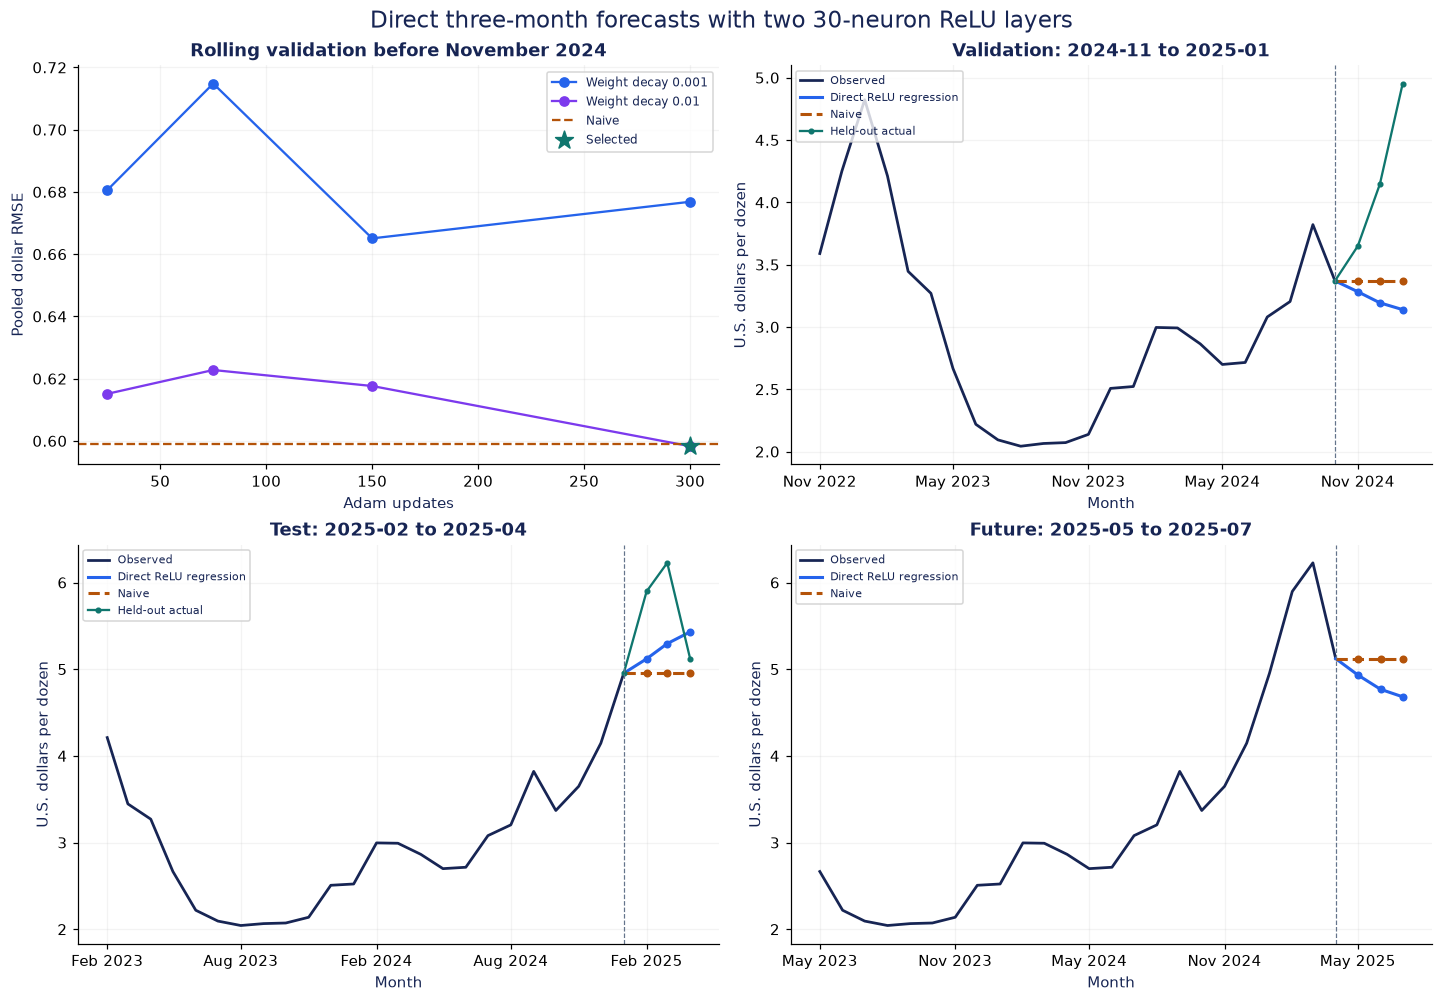

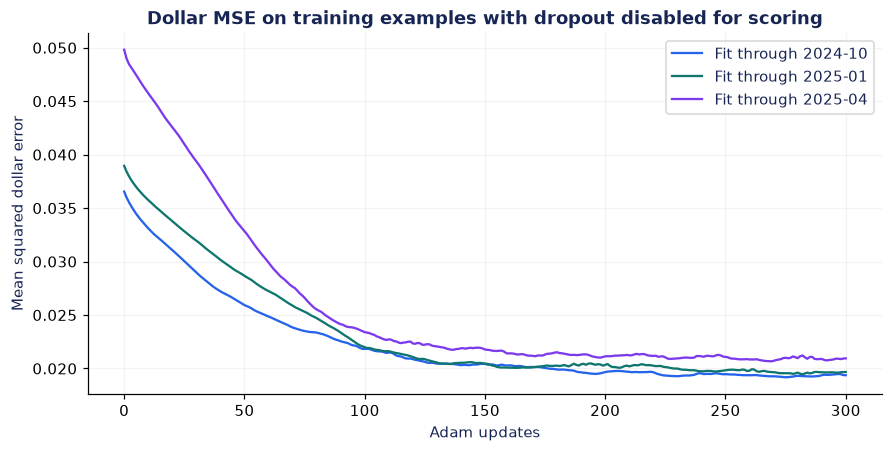

In [5]:
def draw_forecast(ax, stage):
    result = experiments[stage]
    end = result['model']['end']
    past = slice(max(0, end - 24), end)
    origin = dates[end - 1].astype('datetime64[D]')
    forecast_dates = result['dates'].astype('datetime64[D]')
    joined = np.concatenate([[origin], forecast_dates])
    ax.plot(dates[past].astype('datetime64[D]'), prices[past],
            color=COLORS['observed'], label='Observed', lw=1.8)
    for method, color, style in [('Direct ReLU regression', COLORS['gd'], '-'),
                                 ('Naive', COLORS['naive'], '--')]:
        forecast = result['forecasts'][method]
        ax.plot(joined, np.r_[prices[end - 1], forecast], color=color, ls=style, lw=2, label=method)
        ax.scatter(forecast_dates, forecast, color=color, s=18, zorder=3)
    if result['actual'] is not None:
        ax.plot(joined, np.r_[prices[end - 1], result['actual']],
                color=COLORS['actual'], marker='o', ms=3, label='Held-out actual')
    ax.axvline(origin, color='#64748b', ls='--', lw=0.8)
    ax.set(title=f"{stage}: {result['dates'][0]} to {result['dates'][-1]}",
           xlabel='Month', ylabel='U.S. dollars per dozen')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.15)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for decay, color in zip(WEIGHT_DECAYS, ['#2563eb', '#7c3aed']):
    rows = sorted([r for r in cv_scores if r['weight_decay'] == decay], key=lambda r: r['epochs'])
    axes[0, 0].plot([r['epochs'] for r in rows], [r['RMSE'] for r in rows],
                    color=color, marker='o', label=f'Weight decay {decay}')
axes[0, 0].axhline(naive_cv['RMSE'], color=COLORS['naive'], ls='--', label='Naive')
axes[0, 0].scatter([selected['epochs']], [selected['RMSE']], marker='*', s=150,
                   color='#0f766e', zorder=4, label='Selected')
axes[0, 0].set(title='Rolling validation before November 2024',
               xlabel='Adam updates', ylabel='Pooled dollar RMSE')
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(alpha=0.15)
for ax, stage in zip([axes[0, 1], axes[1, 0], axes[1, 1]], origins):
    draw_forecast(ax, stage)
fig.suptitle('Direct three-month forecasts with two 30-neuron ReLU layers', fontsize=15)
fig.savefig(OUT / 'direct_network_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
for stage, color in zip(origins, ['#2563eb', '#0f766e', '#7c3aed']):
    model = experiments[stage]['model']
    ax.plot(model['losses'], color=color, label=f"Fit through {dates[model['end'] - 1]}")
ax.set(title='Dollar MSE on training examples with dropout disabled for scoring',
       xlabel='Adam updates', ylabel='Mean squared dollar error')
ax.grid(alpha=0.15)
ax.legend()
fig.savefig(OUT / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()


## Checks and interpretation

The baseline is a useful comparator, not a performance guarantee. Compare
rolling validation, later validation, and test scores separately. If their
rankings disagree, report that disagreement. The model still has 1,413 parameters
and only one price series, and shocks may not be predictable from past changes.

This experiment changes inputs, targets, loss, forecasting strategy and
regularization together; it does not isolate the effect of any single change.
May–July 2025 are historical forecasts, not current forecasts.

The validation design follows
[rolling-origin evaluation](https://otexts.com/fpp3/tscv.html). The implementation
uses PyTorch's linear layers, ReLU, dropout and Adam. The outputs below include
the selection record, every rolling prediction, all metrics and model weights.


In [6]:
assert [str(d) for d in experiments['Validation']['dates']] == ['2024-11', '2024-12', '2025-01']
assert [str(d) for d in experiments['Test']['dates']] == ['2025-02', '2025-03', '2025-04']
assert [str(d) for d in experiments['Future']['dates']] == ['2025-05', '2025-06', '2025-07']
assert len(cv_rows) == 12 * 3 * len(WEIGHT_DECAYS) * len(CHECKPOINTS)
assert all(np.datetime64(r['date']) < np.datetime64('2024-11') for r in cv_rows)
for result in experiments.values():
    model = result['model']
    assert model['last_target'] == model['end'] - 1
    assert dates[model['last_target']] < result['dates'][0]
    linears = [m for m in model['network'].layers if isinstance(m, nn.Linear)]
    assert [(m.in_features, m.out_features) for m in linears] == [(12, 30), (30, 30), (30, 3)]
    assert sum(isinstance(m, nn.ReLU) for m in model['network'].layers) == 2
    check = predict_direct(model, prices[:model['end']].copy())
    assert np.array_equal(check, result['forecasts']['Direct ReLU regression'])

def save_csv(filename, rows):
    with (OUT / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_csv('cv_folds.csv', cv_folds)
save_csv('cv_scores.csv', cv_scores)
save_csv('cv_predictions.csv', cv_rows)
save_csv('cv_naive_predictions.csv', cv_naive_rows)
save_csv('accuracy.csv', accuracy_rows)
save_csv('comparison_accuracy.csv', comparison_rows)
save_csv('predictions.csv', prediction_rows)
save_csv('fits.csv', fit_rows)
save_csv('learning_curves.csv', loss_rows)
import json
settings = dict(selected_weight_decay=selected['weight_decay'], selected_epochs=selected['epochs'],
    selected_cv_rmse=selected['RMSE'], naive_cv_rmse=naive_cv['RMSE'],
    cv_last_target='2024-10', seed=SEED, learning_rate=LEARNING_RATE, dropout=DROPOUT,
    lags=LAGS, architecture=[12, 30, 30, 3], parameters=parameter_count,
    loss='dollar MSE after price-anchored exponential decoder', source_md5=source_md5)
(OUT / 'selected_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
for stage, result in experiments.items():
    model = result['model']
    torch.save(dict(state_dict=model['network'].state_dict(),
        feature_mean=model['center'].tolist(), feature_scale=model['scale'].tolist(),
        history_end=str(dates[model['end'] - 1]), anchor_price=float(prices[model['end'] - 1]),
        settings=settings), OUT / f'{stage.lower()}_model.pt')
(OUT / 'run_info.txt').write_text(
    f'Python {platform.python_version()}\nNumPy {np.__version__}\n'
    f'Matplotlib {matplotlib.__version__}\nPyTorch {torch.__version__}\n'
    f'Source MD5 {source_md5}\n'+json.dumps(settings, indent=2)+'\n', encoding='utf-8')
for stage in ['Validation', 'Test']:
    rows = [r for r in comparison_rows if r['stage'] == stage]
    winner = min(rows, key=lambda r: r['RMSE'])
    print(f"{stage}: {winner['model']} has the lowest RMSE among these comparisons.")
print('Checks passed. Selection used only rolling outcomes ending by October 2024.')
print(f'Saved results and weights to {OUT}')


Validation: Naive has the lowest RMSE among these comparisons.
Test: Direct ReLU regression has the lowest RMSE among these comparisons.
Checks passed. Selection used only rolling outcomes ending by October 2024.
Saved results and weights to C:\Users\Kelvin\Desktop\Folders\GitHub\egg-onomics\results\direct_neural_network
